<a href="https://colab.research.google.com/github/AMokhtar51/ml-college-project/blob/main/Part_A1_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **1.Import Libraries and Load Data**

**Dataset:** Medical Insurance Cost

In [86]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler

df = pd.read_csv("https://raw.githubusercontent.com/AMokhtar51/ml-college-project/refs/heads/main/part_a_numerical/insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


# **2.Understanding the Dataset**

In [87]:
df.info()
print("Dataset Shape:", df.shape)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
Dataset Shape: (1338, 7)


# **3.Data Quality Assessment**

### 3.1 Checking for Missing Values
Missing values are data entries that are not recorded or are unavailable.
Identifying missing values is essential before preprocessing because they may affect model training and performance.

In [88]:
# Check missing values in each column
df.isnull().sum()

,0
age,0
sex,0
bmi,0
children,0
smoker,0
region,0
charges,0


**Observation:** No missing values were detected in the dataset. Therefore, no missing-value imputation is required.



### 3.2 Checking for Duplicate Rows

Duplicate rows are records containing identical values across all columns. Checking for duplicates helps identify potentially redundant observations before model training.

In [89]:
# Count duplicate rows after first apperance
df.duplicated().sum()

np.int64(1)

In [90]:
# Display duplicated records
df[df.duplicated(keep=False)]

,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


**Observation:** One exact duplicate record was detected in the dataset (rows 195 and 581). Both rows contain identical values across all seven columns. This duplicate will be removed during the data cleaning stage to avoid retaining redundant records.

### 3.3 Checking for Invalid Values

We check the numerical columns for invalid values, such as non-positive ages, non-positive BMI values, negative numbers of children, and negative insurance charges. This helps ensure data quality before model training.


**Cell 1- Check invalid Numerical values**

In [91]:
# Check for invalid numerical values
print("Invalid Age:", (df["age"] <= 0).sum())
print("Invalid BMI:", (df["bmi"] <= 0).sum())
print("Invalid Children:", (df["children"] < 0).sum())
print("Invalid Charges:", (df["charges"] < 0).sum())



Invalid Age: 0
Invalid BMI: 0
Invalid Children: 0
Invalid Charges: 0


**Cell 2- Check invalid categorical values**

In [92]:
# Check for invalid categorical values
print("Invalid Sex:", (~df["sex"].isin(["male", "female"])).sum())
print("Invalid Smoker:", (~df["smoker"].isin(["yes", "no"])).sum())
print("Invalid Region:", (~df["region"].isin(
    ["northeast", "northwest", "southeast", "southwest"]
)).sum())

Invalid Sex: 0
Invalid Smoker: 0
Invalid Region: 0


**Observation:** No invalid values were detected in the numerical or categorical columns based on the applied validation checks. Therefore, no corrections are required for these values.

# **4.Data Cleaning**


### 4.1 Removing Duplicate Rows

An exact duplicate record was identified during the data quality assessment. We remove the additional occurrence while retaining the first occurrence to avoid unnecessary duplication in the dataset.

In [93]:
# Remove duplicate rows
df = df.drop_duplicates()

# Reset the row index
df = df.reset_index(drop=True)

# Check the dataset shape after cleaning
print("Dataset Shape After Cleaning:", df.shape)

Dataset Shape After Cleaning: (1337, 7)


# **5.Exploratory Data Analysis (EDA)**


###5.1 Summary Statistics

Summary statistics provide an overview of the numerical features, including their central tendency, spread, and range. They help us understand the dataset before model training.

In [94]:
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


###5.2 Visualizing Data Distributions

Histograms help visualize the distribution of numerical variables, identify common value ranges, and detect potential skewness or extreme values.

**Distribution of insurance charges**

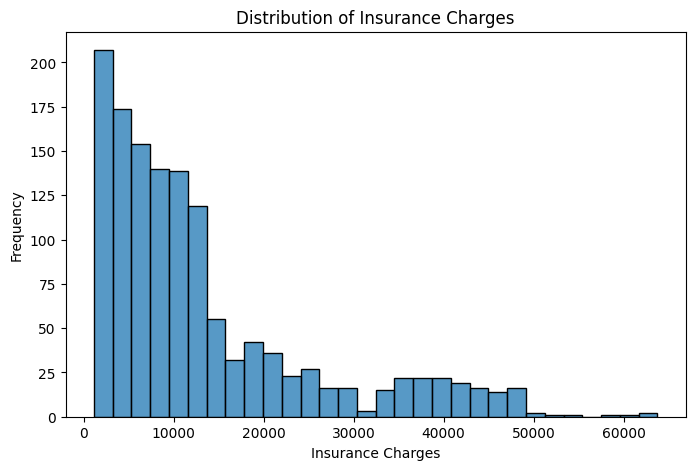

In [95]:
# Plot the distribution of insurance charges w=8 h=5
plt.figure(figsize=(8, 5))

#Actual drawing of histogram
sns.histplot(data=df, x="charges", bins=30)

plt.title("Distribution of Insurance Charges")
plt.xlabel("Insurance Charges")
plt.ylabel("Frequency")

plt.show()

**Observation:** The distribution of insurance charges is right-skewed, with most observations concentrated at lower charge values and fewer observations at higher values. This is consistent with the mean being greater than the median.

**Distribution of age**

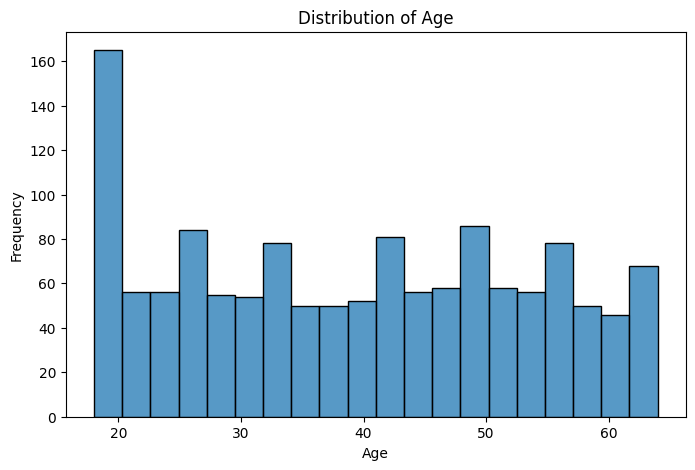

In [96]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="age", bins=20)

plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

**Observation:** The age distribution is relatively uniform across most age ranges, with a noticeable peak among younger individuals aged approximately 18–20.

**Distribution of BMI**

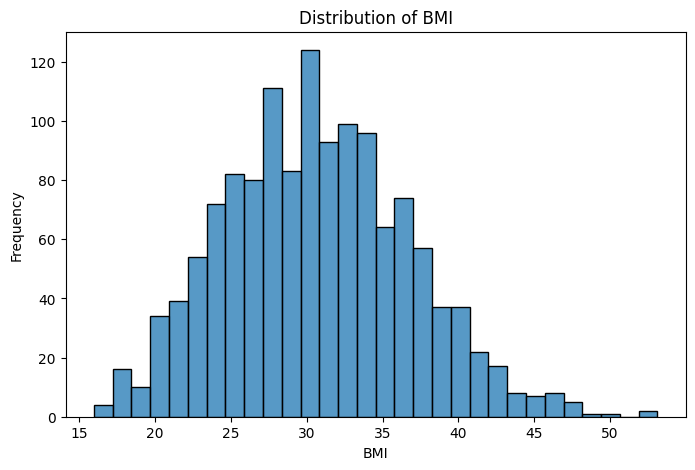

In [97]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="bmi", bins=30)

plt.title("Distribution of BMI")
plt.xlabel("BMI")
plt.ylabel("Frequency")

plt.show()


**Observation:** The BMI distribution is approximately bell-shaped, with most values concentrated between 25 and 35.

**Distribution of Children**

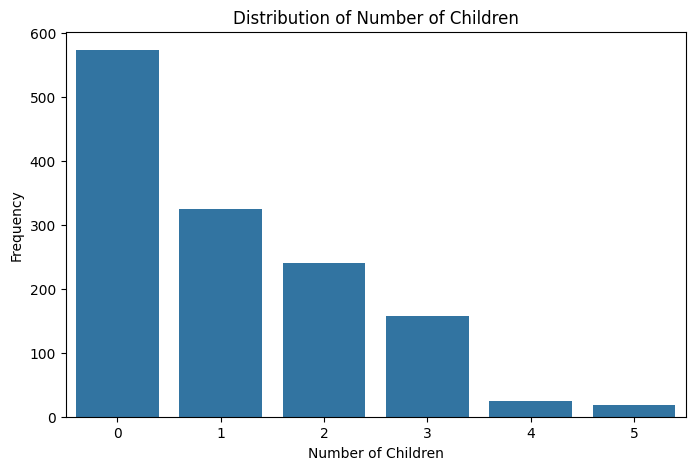

In [98]:
plt.figure(figsize=(8, 5))

# Use countplot to show the frequency of each discrete number of children.
sns.countplot(data=df, x="children")

plt.title("Distribution of Number of Children")
plt.xlabel("Number of Children")
plt.ylabel("Frequency")

plt.show()

**Observation:** Most individuals in the dataset have no children, followed by those with one or two children. The frequency generally decreases as the number of children increases, with four or five children being relatively uncommon.

### 5.3 Correlation Analysis
**5.3.1 Numerical Features Analysis**

Correlation analysis helps identify the strength and direction of linear relationships between numerical features and insurance charges.

In [99]:
# Select numerical columns and calculate their correlations
correlation_matrix = df.select_dtypes(include="number").corr()

# Display the correlation matrix
correlation_matrix

,age,bmi,children,charges
age,1.000000,0.109344,0.041536,0.298308
bmi,0.109344,1.000000,0.012755,0.198401
children,0.041536,0.012755,1.000000,0.067389
charges,0.298308,0.198401,0.067389,1.000000


**Visualizing the Correlation Matrix**

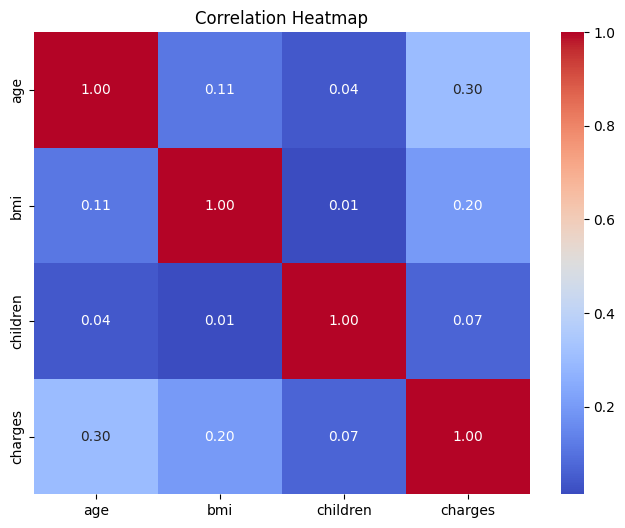

In [100]:
# Visualize correlations between numerical variables
plt.figure(figsize=(8, 6))

sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

**Observation:** Age shows the highest positive correlation with insurance charges among the numerical features (0.30), followed by BMI (0.20). The number of children has a very weak positive correlation with charges (0.07). Overall, the numerical features show relatively weak linear relationships with insurance charges.

**5.3.2 Categorical Features Analysis**

This section explores how insurance charges vary across categorical features, helping identify potential differences between groups.

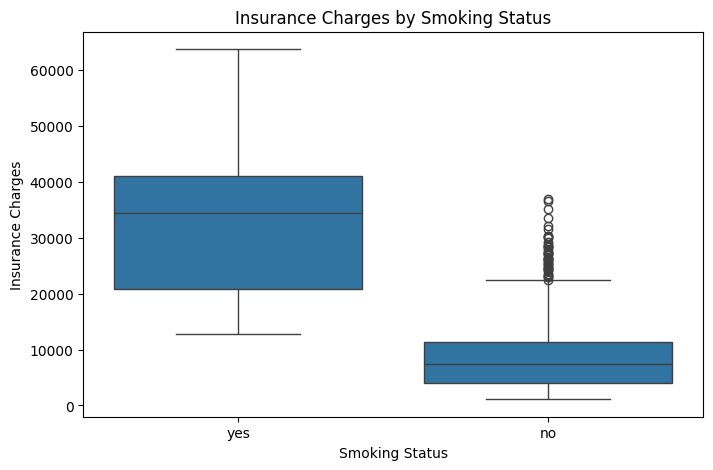

In [101]:
# Compare insurance charges between smokers and non-smokers
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="smoker", y="charges")

plt.title("Insurance Charges by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Insurance Charges")

plt.show()

**Observation:** Smokers generally have significantly higher insurance charges than non-smokers, with a much higher median and a wider spread of costs. Some non-smokers also have unusually high charges, appearing as potential outliers. This suggests that smoking status may be an important feature for predicting insurance charges.

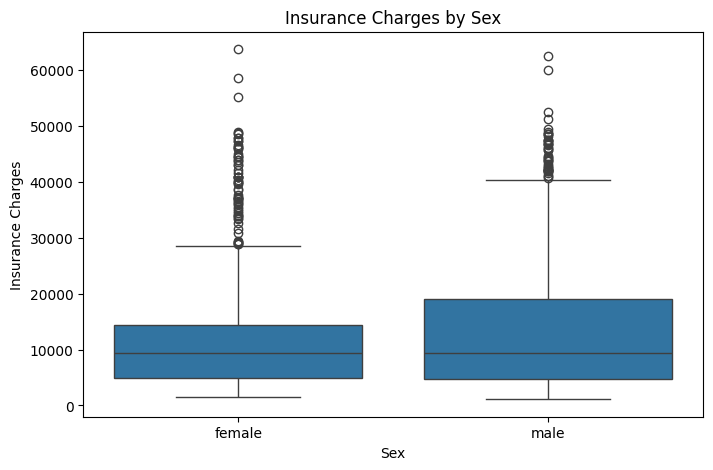

In [102]:
# Compare insurance charges between males and females
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="sex", y="charges")

plt.title("Insurance Charges by Sex")
plt.xlabel("Sex")
plt.ylabel("Insurance Charges")

plt.show()

**Observation:** Insurance charges have similar median values for males and females. However, males show a wider spread in charges, indicating greater variability in the middle 50% of the data. Both groups contain several high-cost outliers. Overall, the difference in insurance charges between males and females is less pronounced than the difference observed between smokers and non-smokers.

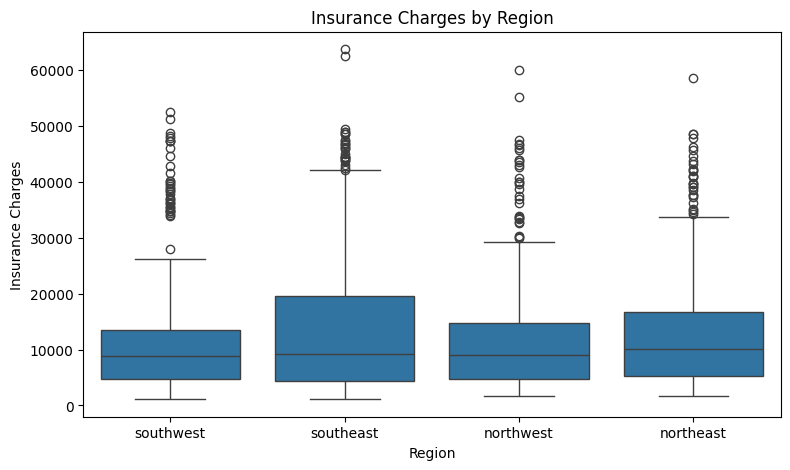

In [103]:
# Compare insurance charges across different regions
plt.figure(figsize=(9, 5))

sns.boxplot(data=df, x="region", y="charges")

plt.title("Insurance Charges by Region")
plt.xlabel("Region")
plt.ylabel("Insurance Charges")

plt.show()

**Observation:** Insurance charges show relatively similar median values across the four regions, with the Northeast having a slightly higher median. The Southeast shows a wider spread of charges, indicating greater variability. All regions contain high-cost potential outliers. Overall, regional differences are less pronounced than the differences observed between smokers and non-smokers.

# **6.Data Splitting and Preprocessing**


## 6.1 Defining Features and Target

The dataset is divided into input features (X) and the target variable (y). The input features contain the information used to predict insurance charges, while the target variable represents the actual insurance cost.

In [104]:
# Define input features (X) and target variable (y)
X = df.drop(columns=["charges"])
y = df["charges"]

# Display their shapes
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (1337, 6)
Target Shape: (1337,)


## 6.2 Train, Validation, and Test Split

The dataset is split into training (70%), validation (15%), and testing (15%) sets. The training set is used to fit the models, the validation set is used for hyperparameter tuning, and the test set is reserved for final evaluation on unseen data.

In [105]:


# Split the dataset into training (70%) and temporary (30%) sets
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42
)

# Split the temporary set equally into validation (15%) and test (15%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42
)

# Check the number of rows in each set
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Training: (935, 6)
Validation: (201, 6)
Testing: (201, 6)


## 6.3 Encoding Categorical Features

One-Hot Encoding is applied to categorical features to convert text categories into numerical values without introducing an artificial order. The encoder is fitted only on the training data to prevent data leakage.

In [106]:
# Select categorical columns
categorical_cols = ["sex", "smoker", "region"]

# Create the One-Hot Encoder
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)

# Learn categories from training data only
encoder.fit(X_train[categorical_cols])

# Apply encoding to each dataset
X_train_encoded = encoder.transform(X_train[categorical_cols])
X_val_encoded = encoder.transform(X_val[categorical_cols])
X_test_encoded = encoder.transform(X_test[categorical_cols])

# Display the new column names
print(encoder.get_feature_names_out(categorical_cols))

['sex_female' 'sex_male' 'smoker_no' 'smoker_yes' 'region_northeast'
 'region_northwest' 'region_southeast' 'region_southwest']


## 6.4 Feature Scaling Numerical Features

StandardScaler is applied to numerical features to standardize their values. This is particularly important for distance-based algorithms such as KNN. The scaler is fitted only on the training data to prevent data leakage.italicized text

In [107]:
# Select numerical columns
numerical_cols = ["age", "bmi", "children"]

# Create the scaler
scaler = StandardScaler()

# Learn the mean and standard deviation from training data
scaler.fit(X_train[numerical_cols])

# Apply the same scaling to all datasets
X_train_scaled = scaler.transform(X_train[numerical_cols])
X_val_scaled = scaler.transform(X_val[numerical_cols])
X_test_scaled = scaler.transform(X_test[numerical_cols])

# Display the first 5 scaled training rows
print(X_train_scaled[:5])

[[ 1.07135822  0.21267146  1.59987002]
 [ 1.14282796  0.01087138 -0.90578906]
 [-1.00126436  2.47814723  0.76465033]
 [ 0.57107001  0.92520013 -0.90578906]
 [ 0.57107001  1.38194928  0.76465033]]


## 6.5 Combining Encoded and Scaled Features

The scaled numerical features and one-hot encoded categorical features are combined to create the final preprocessed datasets for training, validation, and testing.

In [108]:
# Combine scaled numerical and encoded categorical features
X_train_preprocessed = np.hstack((X_train_scaled, X_train_encoded))
X_val_preprocessed = np.hstack((X_val_scaled, X_val_encoded))
X_test_preprocessed = np.hstack((X_test_scaled, X_test_encoded))

# Check the final shapes
print("Training:", X_train_preprocessed.shape)
print("Validation:", X_val_preprocessed.shape)
print("Testing:", X_test_preprocessed.shape)

Training: (935, 11)
Validation: (201, 11)
Testing: (201, 11)


## 6.6 Final Preprocessing Verification

Verify that the preprocessed datasets have consistent feature dimensions, contain only numerical values, and have no missing or infinite values before model training.

In [109]:
# Check that all datasets have the same number of features
print("Same number of features:",
      X_train_preprocessed.shape[1] ==
      X_val_preprocessed.shape[1] ==
      X_test_preprocessed.shape[1])

# Check for missing values
print("Missing values in Training:", np.isnan(X_train_preprocessed).sum())
print("Missing values in Validation:", np.isnan(X_val_preprocessed).sum())
print("Missing values in Testing:", np.isnan(X_test_preprocessed).sum())

# Check that all values are finite
print("All Training values finite:", np.isfinite(X_train_preprocessed).all())
print("All Validation values finite:", np.isfinite(X_val_preprocessed).all())
print("All Testing values finite:", np.isfinite(X_test_preprocessed).all())

# Check the data type
print("Data type:", X_train_preprocessed.dtype)

Same number of features: True
Missing values in Training: 0
Missing values in Validation: 0
Missing values in Testing: 0
All Training values finite: True
All Validation values finite: True
All Testing values finite: True
Data type: float64


## 6.7 Preprocessing Summary

The data preprocessing stage has been successfully completed.

- Removed duplicate records and verified data quality.
- Split the dataset into 70% training, 15% validation, and 15% testing.
- Applied One-Hot Encoding to categorical features.
- Standardized numerical features using StandardScaler.
- Fitted preprocessing transformations exclusively on the training set to prevent data leakage.
- Combined encoded and scaled features into 11 numerical features.
- Verified that the final datasets contain no missing or infinite values.

**The preprocessed datasets are now ready for model training and evaluation.**